# Optimisation différentiable : méthode du gradient à pas optimal

**Niveau :** 4ᵉ année — Sciences des Données et Intelligence Artificielle  
**Outils :** NumPy, SymPy, Pandas, Matplotlib

---

## Plan du notebook

1. Introduction
2. Énoncé de l'exercice
3. Résolution mathématique
4. Implémentation Python
5. Résultats et visualisations
6. Interprétation et conclusion

## Partie 1 — Introduction

### 1.1 L'optimisation différentiable

On cherche le minimum d'une fonction dérivable $f : \mathbb{R}^n \to \mathbb{R}$ :

$$\min_{x \in \mathbb{R}^n} f(x).$$

Les algorithmes de **descente** construisent une suite $x_{k+1} = x_k + \alpha_k d_k$, où $d_k$ est une **direction de descente** ($\nabla f(x_k)^\top d_k < 0$) et $\alpha_k > 0$ un **pas**. Ce notebook prolonge les trois précédents (Newton, quasi-Newton BFGS, gradient à pas fixe et gradient conjugué) et traite la même fonction avec la même donnée initiale.

### 1.2 Du pas fixe au pas optimal

Dans la méthode du gradient à pas fixe, la direction est $d_k = -\nabla f(x_k)$ et le pas $\alpha$ est une constante. Le notebook correspondant a montré la difficulté de ce choix : pour garantir la décroissance depuis $x_0$, il faut $\alpha < 2/L \approx 0{,}04$, où $L$ est la plus grande courbure rencontrée, alors qu'au voisinage du minimum un pas bien plus grand ($\alpha = 1/12$) est plus efficace, mais sans garantie théorique.

La **méthode du gradient à pas optimal** (ou méthode de la plus forte descente avec recherche linéaire exacte, ou méthode de Cauchy) supprime ce choix : à chaque itération, le pas est calculé comme le **minimiseur exact de $f$ le long de la direction $-\nabla f(x_k)$** :

$$\boxed{\,x_{k+1} = x_k - \alpha_k \nabla f(x_k), \qquad \alpha_k \in \arg\min_{\alpha \ge 0}\, \varphi_k(\alpha), \quad \varphi_k(\alpha) = f\bigl(x_k - \alpha \nabla f(x_k)\bigr).\,}$$

Le pas s'adapte ainsi automatiquement à la courbure locale : petit loin du minimum, où la courbure est grande, et plus grand près du minimum.

### 1.3 Propriétés annoncées

Les propriétés suivantes sont démontrées en Partie 3 puis vérifiées numériquement en Partie 5.

- **Décroissance garantie sans connaître $L$.** Le pas optimal fait au moins aussi bien que le pas $1/L$, sans que $L$ intervienne dans l'algorithme.
- **Orthogonalité des gradients successifs :** $\nabla f(x_{k+1})^\top \nabla f(x_k) = 0$. Le chemin suivi est un « zigzag » à angles droits. En dimension 2, cette propriété a une conséquence géométrique forte (§3.3).
- **Cas quadratique :** le pas optimal a une formule fermée et le taux de convergence ne dépend que du conditionnement $\kappa$ du Hessien.

La convergence est **linéaire** et, comme pour le pas fixe, elle se dégrade lorsque $\kappa$ augmente. La méthode reste du premier ordre : seul le gradient est évalué à chaque itération.

## Partie 2 — Énoncé de l'exercice

On considère la même fonction de deux variables que pour les notebooks précédents :

$$f(x,y) = x^4 + y^4 - 4xy.$$

**Questions :**

1. Calculer le gradient et la matrice Hessienne de $f$, puis déterminer et classifier ses points critiques.
2. **Fonction de pas.** Pour une direction quelconque $d$, montrer que $\varphi(\alpha) = f(p + \alpha d)$ est un polynôme de degré 4 et que $\varphi'$ est un polynôme de degré 3 ; en déduire l'existence et le choix du pas optimal.
3. **Propriétés théoriques.** Établir (a) l'orthogonalité des gradients successifs et sa conséquence en dimension 2, (b) une garantie de décroissance indépendante de la constante $L$, (c) la formule du pas optimal et le taux de convergence sur un modèle quadratique, puis les valeurs correspondantes au minimum de $f$.
4. Appliquer la méthode du gradient à pas optimal à partir de $x_0 = (2;\ 1{,}5)$ avec le critère d'arrêt $\|\nabla f(x_k)\|_2 < 10^{-10}$ et présenter le tableau des itérations.
5. Vérifier numériquement l'orthogonalité des gradients, la géométrie du zigzag et la vitesse de convergence par rapport au taux théorique.
6. Présenter les courbes de convergence et les chemins suivis sur les courbes de niveau.
7. Comparer la méthode avec le gradient à pas fixe, le gradient conjugué, BFGS et Newton.
8. Discuter les limites : conditionnement et zigzag, point initial et point selle, racines multiples et coût de la recherche linéaire.

## Partie 3 — Résolution mathématique

### 3.1 Fonction objectif, gradient, Hessien et points critiques

$$f(x,y) = x^4 + y^4 - 4xy, \qquad \nabla f(x,y) = \begin{pmatrix} 4x^3 - 4y \\ 4y^3 - 4x \end{pmatrix}, \qquad H_f(x,y) = \begin{pmatrix} 12x^2 & -4 \\ -4 & 12y^2 \end{pmatrix}.$$

La condition $\nabla f = 0$ donne $y = x^3$ et $x = y^3$, d'où $x = x^9$, soit $x \in \{0, 1, -1\}$ :

| Point | $\det H_f$ | Valeurs propres de $H_f$ | Nature | $f$ |
|---|---|---|---|---|
| $(0,0)$ | $-16$ | $\pm 4$ | point selle | $0$ |
| $(1,1)$ | $128$ | $8,\ 16$ | minimum local strict | $-2$ |
| $(-1,-1)$ | $128$ | $8,\ 16$ | minimum local strict | $-2$ |

Comme $f \to +\infty$ à l'infini, $-2$ est le minimum global, atteint en $(1,1)$ et $(-1,-1)$. Le Hessien ne sert ici qu'à **vérifier** les résultats et à **analyser** la convergence : l'algorithme ne l'utilise pas.

### 3.2 Fonction de pas et polynôme cubique

Soit $p = (x,y)$ un point et $d = (u,v)$ une direction. La fonction $\varphi(\alpha) = f(p + \alpha d)$ est un polynôme de **degré 4** en $\alpha$, de coefficient dominant $u^4 + v^4 > 0$. Sa dérivée est un polynôme de **degré 3** :

$$\varphi'(\alpha) = 4(u^4+v^4)\,\alpha^3 + 12(u^3x+v^3y)\,\alpha^2 + \bigl[12(u^2x^2+v^2y^2) - 8uv\bigr]\alpha + \bigl[4(ux^3+vy^3) - 4(uy+vx)\bigr].$$

On reconnaît $\varphi'(\alpha) = \nabla f(p+\alpha d)^\top d$, avec pour coefficient de $\alpha$ la quantité $d^\top H_f(p)\, d = \varphi''(0)$ et pour terme constant $\nabla f(p)^\top d = \varphi'(0)$. Ces coefficients sont vérifiés symboliquement avec SymPy en §4.4.

**Cas de la méthode étudiée.** Pour $d = -g$ avec $g = \nabla f(p) \neq 0$, on a $\varphi'(0) = -\|g\|^2 < 0$ et $\varphi'(\alpha) \to +\infty$ quand $\alpha \to +\infty$. Par le théorème des valeurs intermédiaires, $\varphi'$ possède **au moins une racine strictement positive**. Comme $\varphi(\alpha) \to +\infty$ et que $\varphi$ est strictement décroissante en $0$, le minimum de $\varphi$ sur $[0,+\infty[$ est atteint en une racine positive de $\varphi'$.

Une cubique a une ou trois racines réelles : on retient, parmi les racines positives, **celle qui minimise $\varphi$** (minimum global le long de la demi-droite). La recherche linéaire est donc **exacte**, et elle ne demande **aucune évaluation supplémentaire du gradient** : les coefficients se calculent à partir de $p$, $d$ et du gradient déjà disponible.

### 3.3 Propriétés de la méthode

**Propriété 1 : orthogonalité des gradients successifs.** Au pas optimal, $\varphi_k'(\alpha_k) = 0$, c'est-à-dire $\nabla f(x_{k+1})^\top d_k = 0$. Avec $d_k = -g_k$ :

$$g_{k+1}^\top g_k = 0.$$

Les déplacements successifs sont donc orthogonaux : $(x_{k+2}-x_{k+1})^\top (x_{k+1}-x_k) = \alpha_{k+1}\alpha_k\, g_{k+1}^\top g_k = 0$. Le chemin est une ligne brisée à angles droits.

**Conséquence en dimension 2.** Si $g_{k+1} \neq 0$, les vecteurs $g_k$ et $g_{k+2}$ sont tous deux orthogonaux à $g_{k+1}$ dans $\mathbb{R}^2$ : ils sont **colinéaires**. Par récurrence, tous les gradients d'indice pair sont colinéaires à $g_0$ et tous ceux d'indice impair sont colinéaires à $g_0^\perp$. Le chemin est donc un **escalier** dont les segments sont alternativement parallèles à $g_0$ et à $g_0^\perp$ : en dimension 2, la méthode revient à une **minimisation alternée le long de deux axes orthogonaux fixes**, définis par le premier gradient. Cette propriété est vérifiée numériquement en §5.4.

**Propriété 2 : décroissance garantie, sans connaître $L$.** Supposons $\nabla f$ $L$-lipschitzienne sur une région contenant les segments $[x_k, x_k - \alpha g_k]$ considérés. Le lemme de descente donne

$$f(x_k - \alpha g_k) \le f(x_k) - \alpha\Bigl(1 - \tfrac{\alpha L}{2}\Bigr)\|g_k\|^2 .$$

Comme $\alpha_k$ minimise $\varphi_k$, on peut comparer avec $\alpha = 1/L$ :

$$f(x_{k+1}) \le f\!\left(x_k - \tfrac1L g_k\right) \le f(x_k) - \frac{1}{2L}\|g_k\|^2 .$$

En sommant sur $k$ et en utilisant $f \ge f_{\min} = -2$, on obtient $\sum_k \|g_k\|^2 \le 2L\,(f(x_0) - f_{\min})$ : la suite $\|g_k\|$ tend vers $0$. De plus, $g_{k+1}^\top g_k = 0$ donne $\|g_k\|^2 = (g_k - g_{k+1})^\top g_k \le L\alpha_k\|g_k\|^2$, soit

$$\alpha_k \ge \frac{1}{L}.$$

Le pas optimal n'est donc jamais plus petit que le pas $1/L$, sans que l'algorithme ait besoin de connaître $L$.

**Propriété 3 : modèle quadratique.** Soit $q(x) = \tfrac12 x^\top A x - b^\top x$ avec $A$ symétrique définie positive, de valeurs propres $\mu = \lambda_{\min} \le \dots \le \lambda_{\max} = L$ et de conditionnement $\kappa = L/\mu$. Avec $g = Ax - b$ et $d = -g$ :

$$\varphi'(\alpha) = -g^\top g + \alpha\, g^\top A g = 0 \quad\Longrightarrow\quad \alpha_k = \frac{g_k^\top g_k}{g_k^\top A g_k} \in \Bigl[\tfrac1L,\ \tfrac1\mu\Bigr] \ \text{(quotient de Rayleigh)}.$$

L'inégalité de Kantorovich donne la garantie de convergence (résultat classique, voir Luenberger) :

$$q(x_{k+1}) - q^\* \le \left(\frac{\kappa-1}{\kappa+1}\right)^2 \bigl(q(x_k) - q^\*\bigr), \qquad \|x_{k+1}-x^\*\|_A \le \frac{\kappa-1}{\kappa+1}\,\|x_k-x^\*\|_A .$$

**Application au minimum $(1,1)$.** Près de $x^\* = (1,1)$, $f$ se comporte comme un modèle quadratique de matrice $A = H_f(1,1) = \begin{pmatrix}12&-4\\-4&12\end{pmatrix}$, de valeurs propres $\mu = 8$ et $L = 16$, soit $\kappa = 2$ (problème très bien conditionné). On attend donc :

- au voisinage du minimum, des pas $\alpha_k$ compris entre $1/16 = 0{,}0625$ et $1/8 = 0{,}125$ ;
- une décroissance de $f - f^\*$ par itération d'un facteur au plus $\bigl(\tfrac{\kappa-1}{\kappa+1}\bigr)^2 = \tfrac19 \approx 0{,}111$ ;
- à titre de comparaison, le meilleur pas fixe local, $\alpha = 2/(\mu+L) = 1/12$, a besoin de connaître $\mu$ et $L$ pour atteindre la même garantie.

### 3.4 Algorithme

1. Choisir $x_0$ et $\varepsilon = 10^{-10}$.
2. Pour $k = 0, 1, \dots$ :
   1. calculer $g_k = \nabla f(x_k)$ ; si $\|g_k\|_2 < \varepsilon$, arrêter ;
   2. direction $d_k = -g_k$ ;
   3. calculer les coefficients de la cubique $\varphi_k'$ et retenir la racine positive $\alpha_k$ qui minimise $\varphi_k$ ;
   4. mettre à jour $x_{k+1} = x_k - \alpha_k g_k$.

**Point initial.** On garde $x_0 = (2;\ 1{,}5)$ : $f(x_0) = 9{,}0625$, $\nabla f(x_0) = (26;\ 5{,}5)$ et $\|\nabla f(x_0)\|_2 \approx 26{,}58$.

## Partie 4 — Implémentation Python

### 4.1 Imports et réglages

In [1]:
import numpy as np
import sympy as sp
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda v: f"{v:.10g}")
pd.set_option("display.width", 180)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

### 4.2 Calcul symbolique (SymPy) et fonctions numériques

Le Hessien exact sert uniquement à **vérifier** les résultats et à **analyser** la convergence ; l'algorithme n'en a pas besoin.

In [2]:
x, y = sp.symbols("x y", real=True)
f_sym    = x**4 + y**4 - 4*x*y
grad_sym = sp.Matrix([sp.diff(f_sym, x), sp.diff(f_sym, y)])
hess_sym = sp.hessian(f_sym, (x, y))

print("f(x,y) =", f_sym)
sp.pprint(grad_sym)
sp.pprint(hess_sym)

f_num    = sp.lambdify((x, y), f_sym, "numpy")
grad_num = sp.lambdify((x, y), grad_sym, "numpy")
hess_num = sp.lambdify((x, y), hess_sym, "numpy")

def f(p):    return float(f_num(p[0], p[1]))
def grad(p): return np.array(grad_num(p[0], p[1]), dtype=float).ravel()
def hess(p): return np.array(hess_num(p[0], p[1]), dtype=float)   # utilisé uniquement pour vérifier/analyser

p0 = np.array([2.0, 1.5])
print("\nf(p0)    =", f(p0))
print("grad(p0) =", grad(p0), "  ||grad(p0)|| =", np.linalg.norm(grad(p0)))

f(x,y) = x**4 - 4*x*y + y**4
⎡   3       ⎤
⎢4⋅x  - 4⋅y ⎥
⎢           ⎥
⎢          3⎥
⎣-4⋅x + 4⋅y ⎦
⎡    2       ⎤
⎢12⋅x    -4  ⎥
⎢            ⎥
⎢           2⎥
⎣ -4    12⋅y ⎦

f(p0)    = 9.0625
grad(p0) = [26.   5.5]   ||grad(p0)|| = 26.575364531836623


### 4.3 Vérification des points critiques et de leur nature

In [3]:
sols = sp.solve(list(grad_sym), (x, y), dict=True)
rows = []
for s in sols:
    H = hess_sym.subs(s)
    eigs = list(H.eigenvals().keys())
    nature = ("minimum local strict" if all(e > 0 for e in eigs)
              else "maximum local strict" if all(e < 0 for e in eigs) else "point selle")
    rows.append({"point": (s[x], s[y]), "f": f_sym.subs(s), "det(H)": H.det(),
                 "valeurs propres": eigs, "nature": nature})
pd.DataFrame(rows)

,point,f,det(H),valeurs propres,nature
0,"(-1, -1)",-2,128,"[16, 8]",minimum local strict
1,"(0, 0)",0,-16,"[-4, 4]",point selle
2,"(1, 1)",-2,128,"[16, 8]",minimum local strict


### 4.4 Étape 1 — Pas optimal pour $f$ (recherche linéaire exacte)

On vérifie d'abord avec SymPy les coefficients de la cubique $\varphi'(\alpha)$ établis au §3.2, ainsi que l'interprétation de ses deux derniers coefficients ($d^\top H_f(p)\, d$ et $\nabla f(p)^\top d$).

In [4]:
a, u, v = sp.symbols("a u v", real=True)
phi  = f_sym.subs({x: x + a*u, y: y + a*v}, simultaneous=True)       # phi(a) = f(p + a d)
dphi = sp.expand(sp.diff(phi, a))
c3, c2, c1, c0 = sp.Poly(dphi, a).all_coeffs()
formules = [4*(u**4 + v**4),
            12*(u**3*x + v**3*y),
            12*(u**2*x**2 + v**2*y**2) - 8*u*v,
            4*(u*x**3 + v*y**3) - 4*(u*y + v*x)]
print("écarts entre coefficients SymPy et formules :", [sp.simplify(c - fo) for c, fo in zip([c3, c2, c1, c0], formules)])

d_vec = sp.Matrix([u, v])
print("c1 - d^T H d      =", sp.simplify(c1 - (d_vec.T * hess_sym * d_vec)[0]))
print("c0 - grad^T d     =", sp.simplify(c0 - (grad_sym.T * d_vec)[0]))

écarts entre coefficients SymPy et formules : [0, 0, 0, 0]
c1 - d^T H d      = 0
c0 - grad^T d     = 0


La fonction `pas_optimal` calcule les racines de la cubique avec `numpy.roots`, ne garde les racines réelles positives, les affine par deux itérations de Newton (précision machine) puis retient celle qui minimise $\varphi$. Le terme constant est calculé par $\nabla f(p)^\top d$ plutôt que par la formule développée : les deux sont égaux (vérification ci-dessus), mais le produit scalaire évite une annulation numérique entre termes de même ordre lorsque le gradient est très petit. La fonction renvoie aussi le **nombre de racines positives** trouvées.

In [5]:
def pas_optimal(p, d):
    # Pas exact : racine positive de phi'(a) = d^T grad f(p + a d) (cubique) qui minimise phi(a) = f(p + a d).
    # Retourne (alpha, nombre de racines réelles positives de la cubique).
    x_, y_ = p
    u_, v_ = d
    coeffs = [4*(u_**4 + v_**4),
              12*(u_**3*x_ + v_**3*y_),
              12*(u_**2*x_**2 + v_**2*y_**2) - 8*u_*v_,
              grad(p) @ d]                                  # = phi'(0) = grad f(p)^T d
    racines = np.roots(coeffs)
    racines = racines[np.abs(racines.imag) < 1e-9 * np.maximum(1.0, np.abs(racines))].real
    racines = racines[racines > 0]
    dcoeffs = np.polyder(coeffs)
    for _ in range(2):                                      # raffinement de Newton (précision machine)
        racines = racines - np.polyval(coeffs, racines) / np.polyval(dcoeffs, racines)
    alpha = racines[np.argmin([f(p + r*d) for r in racines])]
    return alpha, len(racines)

# Test au point initial, direction d = -grad f
g0 = grad(p0); d0 = -g0
alpha0, nb0 = pas_optimal(p0, d0)
grille = np.linspace(0, 0.2, 200001)
phi_grille = f_num(p0[0] + grille*d0[0], p0[1] + grille*d0[1])
print(f"alpha optimal (cubique)            = {alpha0:.10f}   ({nb0} racine positive)")
print(f"alpha optimal (balayage numérique) = {grille[np.argmin(phi_grille)]:.6f}")
print(f"grad f(x0 + alpha d0)^T d0         = {grad(p0 + alpha0*d0) @ d0:.2e}   (attendu : 0)")

alpha optimal (cubique)            = 0.0378204570   (1 racine positive)
alpha optimal (balayage numérique) = 0.037820
grad f(x0 + alpha d0)^T d0         = 1.15e-14   (attendu : 0)


### 4.5 Étape 2 — Algorithme du gradient à pas optimal

Chaque itération suit les étapes : **gradient → direction $-g$ → pas optimal → mise à jour de $x$ → test de convergence**. L'historique enregistre le pas $\alpha_k$, le nombre de racines positives de la cubique et le produit scalaire $g_{k+1}^\top g_k$ (nul en théorie).

In [6]:
def gradient_pas_optimal(p0, tol=1e-10, max_iter=5000):
    # Gradient à pas optimal : x_{k+1} = x_k - alpha_k grad f(x_k), alpha_k minimiseur exact de f(x_k - alpha g_k).
    p = np.array(p0, dtype=float)
    g = grad(p)
    historique = []
    for k in range(max_iter + 1):
        norme_g = np.linalg.norm(g)
        historique.append({"k": k, "x": p[0], "y": p[1], "f(x,y)": f(p), "||grad||": norme_g,
                           "alpha": np.nan, "racines > 0": np.nan, "g_{k+1}^T g_k": np.nan})
        if norme_g < tol or k == max_iter:                 # critère de convergence
            break
        alpha, nb = pas_optimal(p, -g)                     # 1. pas optimal le long de -g
        p_new = p - alpha * g                              # 2. mise à jour des variables
        g_new = grad(p_new)
        historique[-1].update({"alpha": alpha, "racines > 0": nb, "g_{k+1}^T g_k": g_new @ g})
        p, g = p_new, g_new
    return pd.DataFrame(historique)

## Partie 5 — Résultats et visualisations

### 5.1 Première itération : la fonction $\varphi_0$

On trace $\varphi_0(\alpha) = f(x_0 - \alpha\nabla f(x_0))$ et on situe le pas optimal par rapport aux bornes du pas fixe. La constante $L$ est calculée, comme dans le notebook du pas fixe, sur l'ensemble de sous-niveau $\{f \le f(x_0)\}$.

Racines de la cubique phi_0' : [0.097061+0.027832j 0.097061-0.027832j 0.03782 +0.j      ]
phi_0'(0) = grad^T d = -706.2500 = -||g0||^2 = -706.2500
L sur {f <= f(x0)} = 49.540  ->  1/L = 0.0202,  2/L = 0.0404
alpha_0 (optimal)  = 0.037820   (>= 1/L : True)
x_1 = (1.016668, 1.291987),  f(x_1) = -1.399398   (f(x_0) = 9.0625)


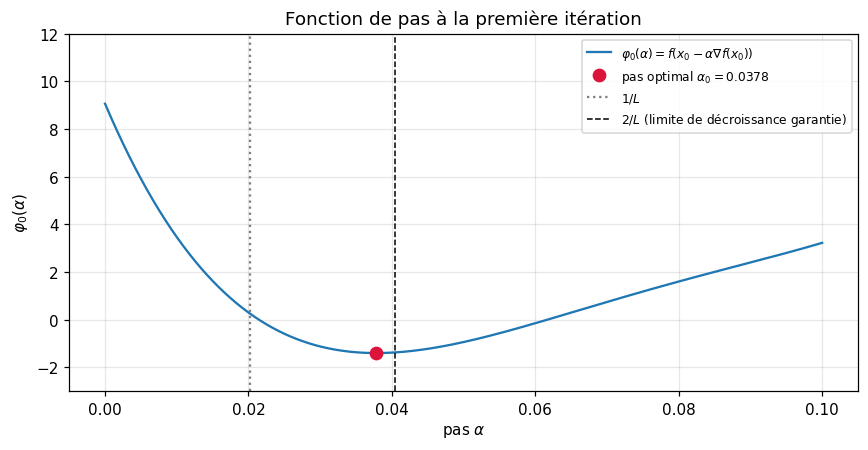

In [7]:
xs_ = np.linspace(-3, 3, 1201)
X_, Y_ = np.meshgrid(xs_, xs_)
Z_ = f_num(X_, Y_)
lam_max = 6*(X_**2 + Y_**2) + np.sqrt(36*(X_**2 - Y_**2)**2 + 16)      # plus grande valeur propre de H_f
L_sous = lam_max[Z_ <= f(p0)].max()

g0 = grad(p0); d0 = -g0
print("Racines de la cubique phi_0' :", np.round(np.roots([4*(d0[0]**4 + d0[1]**4),
      12*(d0[0]**3*p0[0] + d0[1]**3*p0[1]), 12*(d0[0]**2*p0[0]**2 + d0[1]**2*p0[1]**2) - 8*d0[0]*d0[1], g0 @ d0]), 6))
print(f"phi_0'(0) = grad^T d = {g0 @ d0:.4f} = -||g0||^2 = {-g0 @ g0:.4f}")
print(f"L sur {{f <= f(x0)}} = {L_sous:.3f}  ->  1/L = {1/L_sous:.4f},  2/L = {2/L_sous:.4f}")
print(f"alpha_0 (optimal)  = {alpha0:.6f}   (>= 1/L : {alpha0 >= 1/L_sous})")
x1 = p0 + alpha0*d0
print(f"x_1 = ({x1[0]:.6f}, {x1[1]:.6f}),  f(x_1) = {f(x1):.6f}   (f(x_0) = {f(p0):.4f})")

al = np.linspace(0, 0.10, 600)
phi_al = f_num(p0[0] + al*d0[0], p0[1] + al*d0[1])
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(al, phi_al, color="tab:blue", label=r"$\varphi_0(\alpha)=f(x_0-\alpha\nabla f(x_0))$")
ax.plot(alpha0, f(x1), "o", color="crimson", ms=8, label=fr"pas optimal $\alpha_0={alpha0:.4f}$")
ax.axvline(1/L_sous, color="gray", ls=":", label=r"$1/L$")
ax.axvline(2/L_sous, color="black", ls="--", lw=1, label=r"$2/L$ (limite de décroissance garantie)")
ax.set_ylim(-3, 12); ax.set_xlabel(r"pas $\alpha$"); ax.set_ylabel(r"$\varphi_0(\alpha)$")
ax.set_title("Fonction de pas à la première itération"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 5.2 Tableau des itérations

Les colonnes `alpha` et `racines > 0` donnent le pas optimal $\alpha_k$ et le nombre de racines positives de la cubique $\varphi_k'$. La colonne `g_{k+1}^T g_k` doit être nulle (propriété 1).

In [8]:
res = gradient_pas_optimal([2.0, 1.5], tol=1e-10)
res

,k,x,y,"f(x,y)",||grad||,alpha,racines > 0,g_{k+1}^T g_k
0,0,2,1.5,9.0625,26.57536453,0.03782045704,1,-1.154631946e-14
1,1,1.016668117,1.291987486,-1.399397564,4.660739619,0.05617026005,1,-1.969570807e-15
2,2,1.070848832,1.035860468,-1.970695677,0.7854055813,0.08869350162,1,4.583481687e-16
3,3,1.002696629,1.021443656,-1.997388957,0.257673472,0.07188499379,1,-1.468643666e-16
4,4,1.006530093,1.003321826,-1.999763445,0.06703802594,0.09559241767,1,6.974672533e-17
5,5,1.000260508,1.001995567,-1.999977747,0.02346052027,0.07327716756,1,-2.199978912e-17
6,6,1.000616295,1.000313666,-1.999997903,0.006281427924,0.09626678318,1,5.341599001e-18
7,7,1.000024694,1.00018852,-1.999999802,0.002211774523,0.07340865465,1,2.880662605e-18
8,8,1.000058296,1.000029672,-1.999999981,0.0005937656201,0.0963307812,1,-6.863944393e-20
9,9,1.000002337,1.000017834,-1.999999998,0.0002091943077,0.07342109334,1,-3.189882091e-19


### 5.3 Analyse de l'erreur et vitesse de convergence

Le minimum exact est $x^\* = (1,1)$. On calcule $e_k = \|x_k - x^\*\|_2$, l'écart $f(x_k) - f^\*$ avec $f^\* = -2$, et leurs rapports successifs. Le taux théorique sur $f - f^\*$ est $\bigl(\tfrac{\kappa-1}{\kappa+1}\bigr)^2$ avec $\kappa = 16/8 = 2$ (§3.3). Les écarts $f - f^\*$ inférieurs à $10^{-12}$ (affichés `NaN`) sont dominés par les erreurs d'arrondi et exclus de l'analyse.

In [9]:
x_star = np.array([1.0, 1.0]); f_star = -2.0
res["erreur"] = np.linalg.norm(res[["x", "y"]].values - x_star, axis=1)
res["e_{k+1}/e_k"] = np.r_[res["erreur"].values[1:] / res["erreur"].values[:-1], np.nan]
gap = res["f(x,y)"].values - f_star
res["f-f*"] = np.where(gap > 1e-12, gap, np.nan)
rapport = np.full(len(gap), np.nan)
with np.errstate(all="ignore"):
    rapport[:-1] = np.where((gap[:-1] > 1e-12) & (gap[1:] > 1e-12), gap[1:] / gap[:-1], np.nan)
res["(f-f*)_{k+1}/(f-f*)_k"] = rapport

mu_loc, L_loc = np.linalg.eigvalsh(hess(x_star))
kappa_loc = L_loc / mu_loc
rho_f = ((kappa_loc - 1) / (kappa_loc + 1))**2
p_fin = res[["x", "y"]].values[-1]

print(f"Itérations effectuées : {len(res)-1}")
print(f"Point final           : ({p_fin[0]:.12f}, {p_fin[1]:.12f})")
print(f"f au point final      : {res['f(x,y)'].values[-1]:.12f}   (valeur théorique : -2)")
print(f"||grad|| final        : {res['||grad||'].values[-1]:.2e}")
print(f"f ne croît jamais (tolérance 1e-14) : {bool(np.all(np.diff(res['f(x,y)'].values) <= 1e-14))}")
print(f"Valeurs propres de H_f(x*) : {mu_loc:.0f} et {L_loc:.0f}  ->  kappa = {kappa_loc:.0f}")

masque = ~np.isnan(rapport[:-1]) & (res["k"].values[:-1] >= 4)
ratios_f = rapport[:-1][masque]
print(f"\nRapport (f-f*)_(k+1)/(f-f*)_k (k >= 4) : médiane = {np.median(ratios_f):.4f},  max = {ratios_f.max():.4f}")
print(f"Taux théorique ((kappa-1)/(kappa+1))^2   : {rho_f:.4f}   (borne respectée : {bool(ratios_f.max() <= rho_f)})")
e_ratios = res["e_{k+1}/e_k"].values[4:-1]
mg = np.sqrt(e_ratios[-2]*e_ratios[-1])
print(f"Rapport e_(k+1)/e_k (k >= 4) : valeurs alternées {e_ratios[-2]:.4f} / {e_ratios[-1]:.4f}  (moyenne géométrique {mg:.4f}, carré {mg**2:.4f})")
res[["k", "erreur", "e_{k+1}/e_k", "f-f*", "(f-f*)_{k+1}/(f-f*)_k"]]

Itérations effectuées : 22
Point final           : (1.000000000004, 1.000000000002)
f au point final      : -2.000000000000   (valeur théorique : -2)
||grad|| final        : 4.03e-11
f ne croît jamais (tolérance 1e-14) : True
Valeurs propres de H_f(x*) : 8 et 16  ->  kappa = 2

Rapport (f-f*)_(k+1)/(f-f*)_k (k >= 4) : médiane = 0.0946,  max = 0.0946
Taux théorique ((kappa-1)/(kappa+1))^2   : 0.1111   (borne respectée : True)
Rapport e_(k+1)/e_k (k >= 4) : valeurs alternées 0.2750 / 0.3441  (moyenne géométrique 0.3076, carré 0.0946)


,k,erreur,e_{k+1}/e_k,f-f*,(f-f*)_{k+1}/(f-f*)_k
0,0,1.118033989,0.2615867248,11.0625,0.05429174566
1,1,0.2924628494,0.2715126692,0.6006024363,0.04879154906
2,2,0.07940736887,0.2721730676,0.02930432324,0.08910093369
3,3,0.02161254717,0.3389898568,0.002611042562,0.09059787343
4,4,0.007326434271,0.2746901314,0.0002365549035,0.09407264704
5,5,0.002012499193,0.3436147232,2.225334594e-05,0.09423535422
6,6,0.0006915243531,0.2749436692,2.097051938e-06,0.09456265286
7,7,0.000190130243,0.3440435313,1.983027944e-07,0.09457823972
8,8,6.54130802e-05,0.2749677952,1.875512923e-08,0.09460922153
9,9,1.798649044e-05,0.3440840269,1.774408176e-09,0.09461041262


### 5.4 Orthogonalité des gradients et géométrie du zigzag

On vérifie : (i) $g_{k+1}^\top g_k = 0$ ; (ii) en dimension 2, la colinéarité de $g_{k+2}$ et $g_k$ ; (iii) que les pas $\alpha_k$ restent dans $[1/16,\, 1/8]$, intervalle prévu par la théorie au voisinage du minimum. Les itérations où $\|g\| < 10^{-7}$ sont exclues des deux premiers tests, car le gradient y est de l'ordre des erreurs d'arrondi.

In [10]:
P = res[["x", "y"]].values
G = np.array([grad(p) for p in P])
nG = np.linalg.norm(G, axis=1)

cos1 = np.array([G[k] @ G[k+1] / (nG[k]*nG[k+1]) for k in range(len(G)-1)])
cos2 = np.array([G[k] @ G[k+2] / (nG[k]*nG[k+2]) for k in range(len(G)-2)])
m1 = nG[1:] > 1e-7
m2 = nG[2:] > 1e-7
print(f"max |cos(g_k, g_(k+1))|          = {np.abs(cos1[m1]).max():.2e}   (attendu : 0, orthogonalité)")
print(f"min |cos(g_k, g_(k+2))|          = {np.abs(cos2[m2]).min():.12f}   (attendu : 1, colinéarité en dimension 2)")

alphas = res["alpha"].dropna().values
print(f"\nPas alpha_k : min = {alphas.min():.4f},  max = {alphas.max():.4f}")
print(f"Pas alpha_k pour k >= 8 : alternance {alphas[8]:.5f} / {alphas[9]:.5f}")
print(f"Intervalle théorique [1/16, 1/8] = [0.0625, 0.125] ;  tous les pas k >= 4 y sont : {bool(np.all((alphas[4:] >= 1/16) & (alphas[4:] <= 1/8)))}")
print(f"Tous les pas vérifient alpha_k >= 1/L = {1/L_sous:.4f} (propriété 2) : {bool(np.all(alphas >= 1/L_sous))}")

max |cos(g_k, g_(k+1))|          = 5.60e-09   (attendu : 0, orthogonalité)
min |cos(g_k, g_(k+2))|          = 1.000000000000   (attendu : 1, colinéarité en dimension 2)

Pas alpha_k : min = 0.0378,  max = 0.0963
Pas alpha_k pour k >= 8 : alternance 0.09633 / 0.07342
Intervalle théorique [1/16, 1/8] = [0.0625, 0.125] ;  tous les pas k >= 4 y sont : True
Tous les pas vérifient alpha_k >= 1/L = 0.0202 (propriété 2) : True


**Escalier dans le repère des deux axes.** On exprime les itérés dans le repère orthonormé $(e_1, e_2)$ avec $e_1 = g_0/\|g_0\|$ et $e_2 = e_1^\perp$, centré en $x^\*$. Si la propriété de colinéarité est exacte, chaque itération ne modifie qu'**une seule** de ces deux coordonnées, alternativement.

Variation de la coordonnée s (selon g_0)    aux 8 premières itérations : [1.00509e+00 0.00000e+00 6.96600e-02 0.00000e+00 6.41000e-03 0.00000e+00
 6.00000e-04 0.00000e+00]
Variation de la coordonnée t (selon g_0^perp) aux 8 premières itérations : [0.0000e+00 2.6179e-01 0.0000e+00 1.8520e-02 0.0000e+00 1.7200e-03
 0.0000e+00 1.6000e-04]


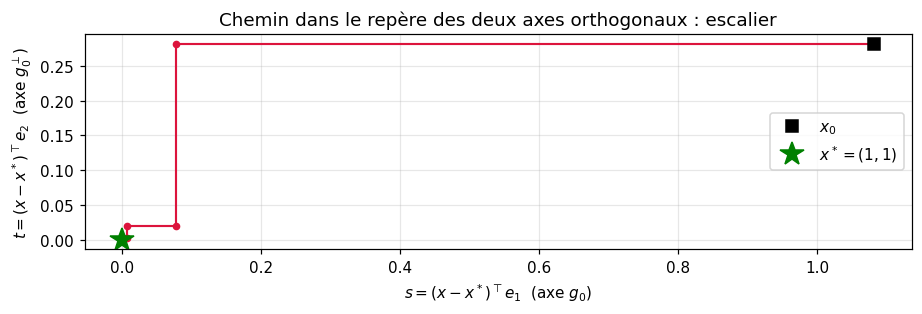

In [11]:
e1 = G[0] / nG[0]
e2 = np.array([-e1[1], e1[0]])
S = (P - x_star) @ e1
T = (P - x_star) @ e2

dS, dT = np.abs(np.diff(S)), np.abs(np.diff(T))
print("Variation de la coordonnée s (selon g_0)    aux 8 premières itérations :", np.round(dS[:8], 5))
print("Variation de la coordonnée t (selon g_0^perp) aux 8 premières itérations :", np.round(dT[:8], 5))

fig, ax = plt.subplots(figsize=(8.4, 4.4))
ax.plot(S, T, "o-", color="crimson", lw=1.4, ms=4)
ax.plot(S[0], T[0], "ks", ms=8, label="$x_0$")
ax.plot(0, 0, "g*", ms=16, label="$x^*=(1,1)$")
ax.set_xlabel(r"$s = (x-x^*)^\top e_1$  (axe $g_0$)"); ax.set_ylabel(r"$t = (x-x^*)^\top e_2$  (axe $g_0^\perp$)")
ax.set_title("Chemin dans le repère des deux axes orthogonaux : escalier")
ax.set_aspect("equal"); ax.legend(loc="center right"); plt.tight_layout(); plt.show()

### 5.5 Courbes de convergence

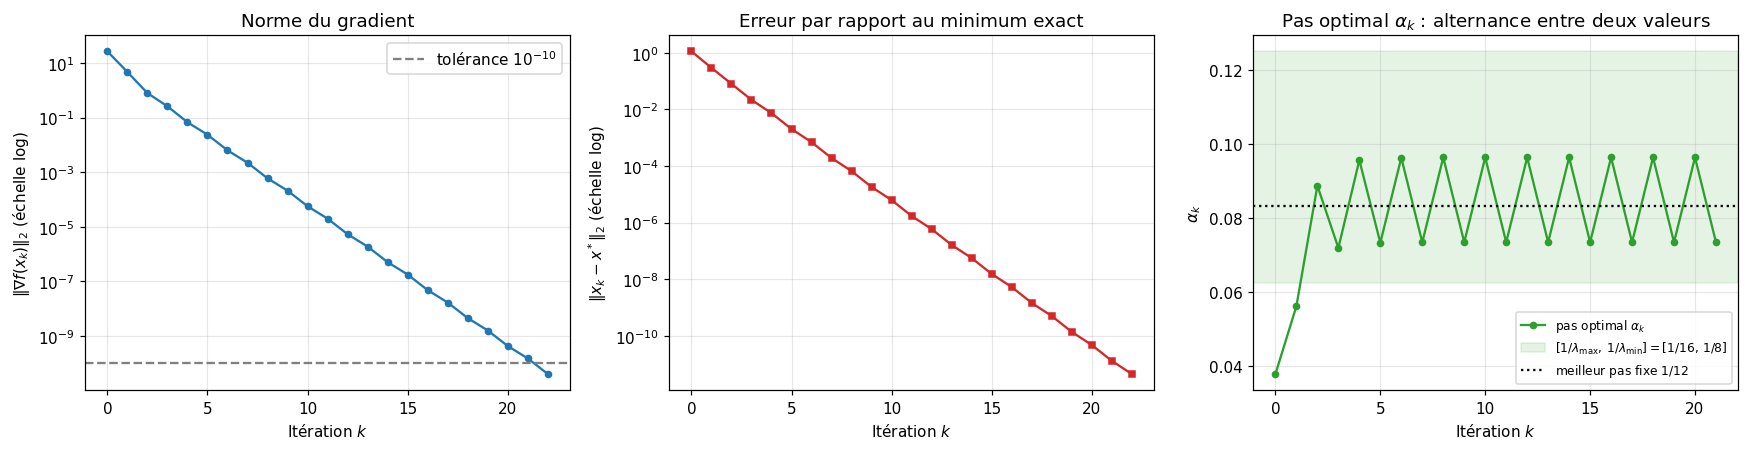

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))

ax[0].semilogy(res["k"], res["||grad||"], "o-", ms=4, color="tab:blue")
ax[0].axhline(1e-10, color="gray", ls="--", label="tolérance $10^{-10}$")
ax[0].set_title("Norme du gradient")
ax[0].set_xlabel("Itération $k$"); ax[0].set_ylabel(r"$\|\nabla f(x_k)\|_2$ (échelle log)"); ax[0].legend()

ax[1].semilogy(res["k"], res["erreur"].clip(lower=1e-17), "s-", ms=4, color="tab:red")
ax[1].set_title("Erreur par rapport au minimum exact")
ax[1].set_xlabel("Itération $k$"); ax[1].set_ylabel(r"$\|x_k - x^*\|_2$ (échelle log)")

ax[2].plot(res["k"][:-1], alphas, "o-", ms=4, color="tab:green", label=r"pas optimal $\alpha_k$")
ax[2].axhspan(1/16, 1/8, color="tab:green", alpha=0.12, label=r"$[1/\lambda_{\max},\,1/\lambda_{\min}]=[1/16,\,1/8]$")
ax[2].axhline(1/12, color="black", ls=":", label=r"meilleur pas fixe $1/12$")
ax[2].set_title(r"Pas optimal $\alpha_k$ : alternance entre deux valeurs")
ax[2].set_xlabel("Itération $k$"); ax[2].set_ylabel(r"$\alpha_k$"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 5.6 Courbes de niveau et chemin suivi

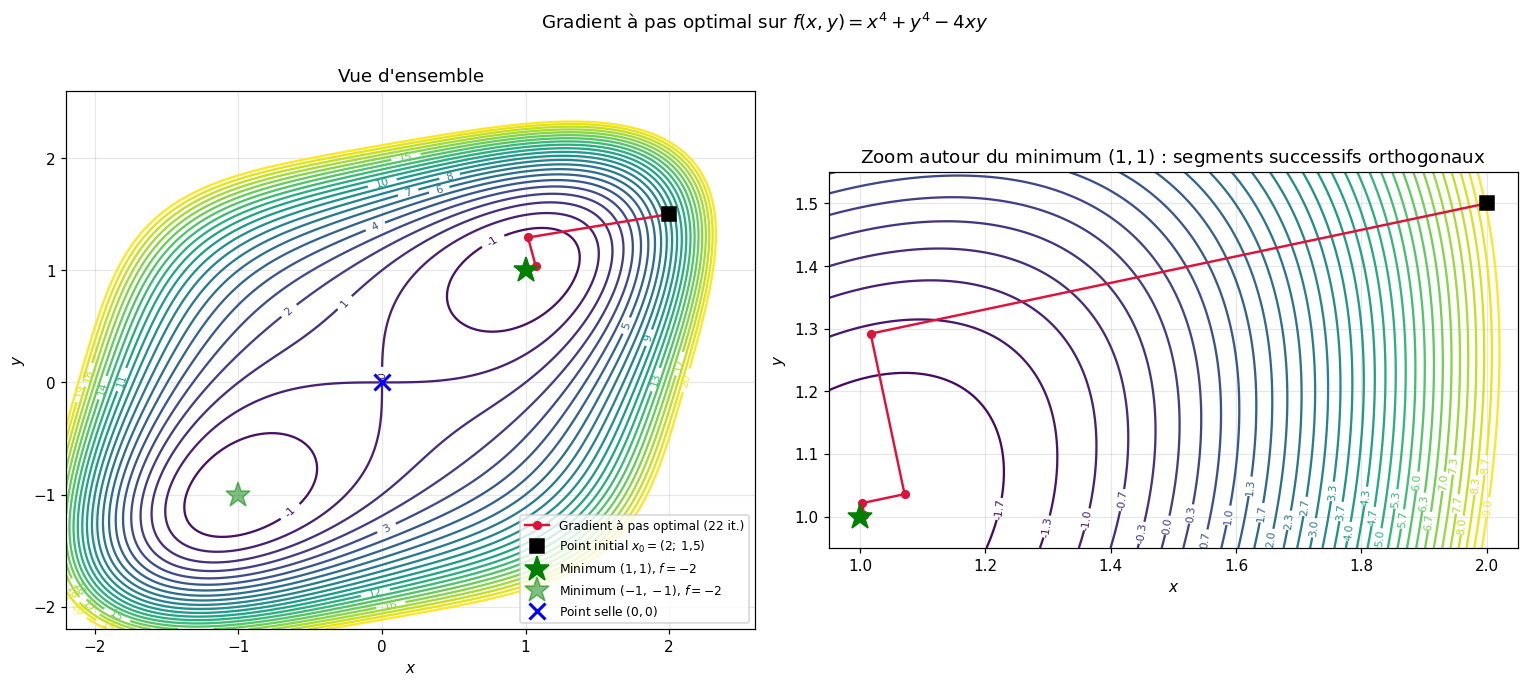

In [13]:
xs = np.linspace(-2.2, 2.6, 400); ys = np.linspace(-2.2, 2.6, 400)
X, Y = np.meshgrid(xs, ys); Z = f_num(X, Y)

fig, ax = plt.subplots(1, 2, figsize=(14, 6.2))
cs = ax[0].contour(X, Y, Z, levels=np.linspace(-2, 20, 23), cmap="viridis")
ax[0].clabel(cs, inline=True, fontsize=7, fmt="%.0f")
ax[0].plot(res["x"], res["y"], "o-", color="crimson", lw=1.6, ms=5, label="Gradient à pas optimal (%d it.)" % (len(res)-1))
ax[0].plot(2.0, 1.5, "ks", ms=9, label="Point initial $x_0=(2;\\,1{,}5)$")
ax[0].plot(1, 1, "g*", ms=17, label="Minimum $(1,1)$, $f=-2$")
ax[0].plot(-1, -1, "g*", ms=17, alpha=0.5, label="Minimum $(-1,-1)$, $f=-2$")
ax[0].plot(0, 0, "bx", ms=11, mew=2, label="Point selle $(0,0)$")
ax[0].set_title("Vue d'ensemble"); ax[0].set_xlabel("$x$"); ax[0].set_ylabel("$y$"); ax[0].legend(loc="lower right", fontsize=8)

xz = np.linspace(0.95, 2.05, 300); yz = np.linspace(0.95, 1.55, 300)
Xz, Yz = np.meshgrid(xz, yz); Zz = f_num(Xz, Yz)
cs2 = ax[1].contour(Xz, Yz, Zz, levels=np.linspace(-2, 9, 34), cmap="viridis")
ax[1].clabel(cs2, inline=True, fontsize=7, fmt="%.1f")
ax[1].plot(res["x"], res["y"], "o-", color="crimson", lw=1.6, ms=5)
ax[1].plot(1, 1, "g*", ms=17); ax[1].plot(2.0, 1.5, "ks", ms=9)
ax[1].set_xlim(0.95, 2.05); ax[1].set_ylim(0.95, 1.55)
ax[1].set_title("Zoom autour du minimum $(1,1)$ : segments successifs orthogonaux")
ax[1].set_xlabel("$x$"); ax[1].set_ylabel("$y$"); ax[1].set_aspect("equal", adjustable="box")
plt.suptitle("Gradient à pas optimal sur $f(x,y)=x^4+y^4-4xy$", y=1.0)
plt.tight_layout(); plt.show()

### 5.7 Comparaison avec le pas fixe, le gradient conjugué, BFGS et Newton

On reprend les implémentations des notebooks précédents (mêmes fonctions, même point initial, même tolérance) pour comparer les familles de méthodes.

In [14]:
def gradient_pas_fixe(p0, alpha, tol=1e-10, max_iter=20000, seuil_div=1e8):
    p = np.array(p0, dtype=float); hist = []
    for k in range(max_iter + 1):
        g = grad(p); ng = np.linalg.norm(g)
        hist.append({"k": k, "x": p[0], "y": p[1], "f(x,y)": f(p), "||grad||": ng})
        if ng < tol or k == max_iter: break
        if not np.isfinite(ng) or ng > seuil_div: break
        p = p - alpha * g
    return pd.DataFrame(hist)

def gradient_conjugue(p0, variante="FR", tol=1e-10, max_iter=500):
    p = np.array(p0, dtype=float); g = grad(p); d = -g; hist = []
    for k in range(max_iter + 1):
        ng = np.linalg.norm(g)
        hist.append({"k": k, "x": p[0], "y": p[1], "f(x,y)": f(p), "||grad||": ng})
        if ng < tol or k == max_iter: break
        if g @ d >= 0: d = -g
        alpha, _ = pas_optimal(p, d)
        p_new = p + alpha * d; g_new = grad(p_new)
        beta = (g_new @ g_new) / (g @ g) if variante == "FR" else max(0.0, g_new @ (g_new - g) / (g @ g))
        d = -g_new + beta * d; p, g = p_new, g_new
    return pd.DataFrame(hist)

def newton(p0, tol=1e-10, max_iter=50):
    p = np.array(p0, dtype=float); hist = []
    for k in range(max_iter + 1):
        g = grad(p)
        hist.append({"k": k, "x": p[0], "y": p[1], "f(x,y)": f(p), "||grad||": np.linalg.norm(g)})
        if np.linalg.norm(g) < tol or k == max_iter: break
        p = p + np.linalg.solve(hess(p), -g)
    return pd.DataFrame(hist)

def armijo(p, d, g, alpha0=1.0, c1=1e-4, facteur=0.5, max_red=60):
    alpha = alpha0; f0, pente = f(p), g @ d
    for _ in range(max_red):
        if f(p + alpha * d) <= f0 + c1 * alpha * pente: return alpha
        alpha *= facteur
    return alpha

def bfgs(p0, tol=1e-10, max_iter=200):
    p = np.array(p0, dtype=float); n = len(p); H = np.eye(n); g = grad(p); hist = []
    for k in range(max_iter + 1):
        ng = np.linalg.norm(g)
        hist.append({"k": k, "x": p[0], "y": p[1], "f(x,y)": f(p), "||grad||": ng})
        if ng < tol or k == max_iter: break
        d = -H @ g
        if g @ d >= 0: H, d = np.eye(n), -g
        alpha = armijo(p, d, g, min(1.0, 1.0 / ng) if k == 0 else 1.0)
        s = alpha * d; p_new = p + s; g_new = grad(p_new); yk = g_new - g
        if s @ yk > 1e-12 * np.linalg.norm(s) * np.linalg.norm(yk):
            rho = 1.0 / (yk @ s); V = np.eye(n) - rho * np.outer(s, yk)
            H = V @ H @ V.T + rho * np.outer(s, s)
        p, g = p_new, g_new
    return pd.DataFrame(hist)

res_fixe   = gradient_pas_fixe([2.0, 1.5], 0.04)
res_fixe12 = gradient_pas_fixe([2.0, 1.5], 1/12)
res_fr     = gradient_conjugue([2.0, 1.5], "FR")
res_pr     = gradient_conjugue([2.0, 1.5], "PR+")
res_bfgs   = bfgs([2.0, 1.5])
res_newton = newton([2.0, 1.5])

methodes = [("Gradient à pas fixe (α = 0,04)", res_fixe, "non", "non", "aucune (pas constant)", "O(n)"),
            ("Gradient à pas fixe (α = 1/12)", res_fixe12, "non", "non", "aucune (pas constant)", "O(n)"),
            ("Gradient à pas optimal", res, "non", "non", "exacte (cubique)", "O(n) + cubique"),
            ("Gradient conjugué FR", res_fr, "non", "non", "exacte (cubique)", "O(n) + cubique"),
            ("Gradient conjugué PR+", res_pr, "non", "non", "exacte (cubique)", "O(n) + cubique"),
            ("BFGS (quasi-Newton)", res_bfgs, "non", "non", "Armijo", "O(n²)"),
            ("Newton", res_newton, "oui", "oui", "aucune (pas 1)", "O(n²) + O(n³)")]
pd.DataFrame({
    "méthode": [m[0] for m in methodes],
    "itérations": [len(m[1]) - 1 for m in methodes],
    "tolérance atteinte": [bool(m[1]["||grad||"].values[-1] < 1e-10) for m in methodes],
    "f final": [m[1]["f(x,y)"].values[-1] for m in methodes],
    "||grad|| final": [f"{m[1]['||grad||'].values[-1]:.1e}" for m in methodes],
    "Hessien exact requis": [m[2] for m in methodes],
    "système linéaire": [m[3] for m in methodes],
    "pas": [m[4] for m in methodes],
    "coût/itération (hors f, ∇f)": [m[5] for m in methodes]})

,méthode,itérations,tolérance atteinte,f final,||grad|| final,Hessien exact requis,système linéaire,pas,"coût/itération (hors f, ∇f)"
0,"Gradient à pas fixe (α = 0,04)",61,True,-2,7.8e-11,non,non,aucune (pas constant),O(n)
1,Gradient à pas fixe (α = 1/12),29,True,-2,3.7e-11,non,non,aucune (pas constant),O(n)
2,Gradient à pas optimal,22,True,-2,4.0e-11,non,non,exacte (cubique),O(n) + cubique
3,Gradient conjugué FR,13,True,-2,9.6e-11,non,non,exacte (cubique),O(n) + cubique
4,Gradient conjugué PR+,6,True,-2,1.4e-13,non,non,exacte (cubique),O(n) + cubique
5,BFGS (quasi-Newton),13,True,-2,1.2e-12,non,non,Armijo,O(n²)
6,Newton,6,True,-2,2.0e-13,oui,oui,aucune (pas 1),O(n²) + O(n³)


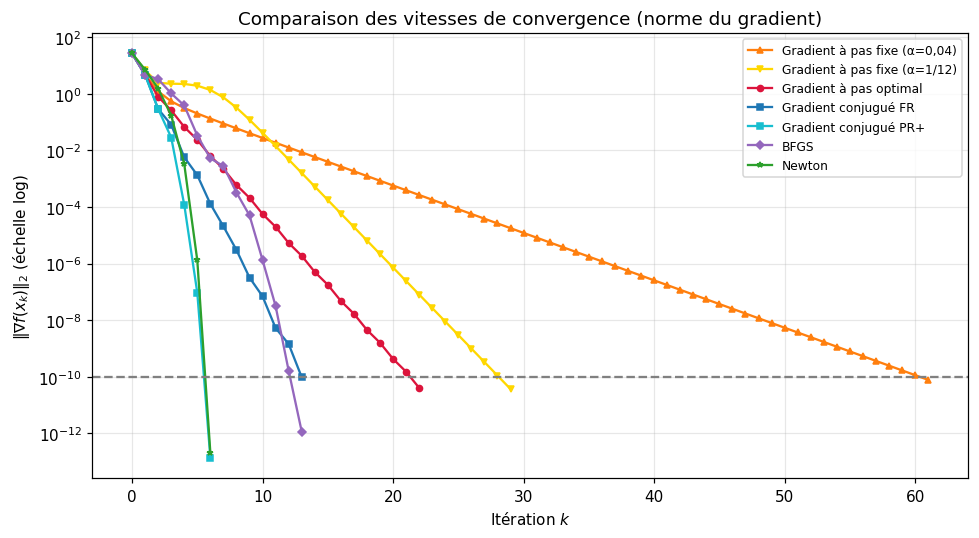

In [15]:
fig, ax = plt.subplots(figsize=(9, 5))
for nom, r, c, mk in [("Gradient à pas fixe (α=0,04)", res_fixe, "tab:orange", "^"),
                      ("Gradient à pas fixe (α=1/12)", res_fixe12, "gold", "v"),
                      ("Gradient à pas optimal", res, "crimson", "o"),
                      ("Gradient conjugué FR", res_fr, "tab:blue", "s"),
                      ("Gradient conjugué PR+", res_pr, "tab:cyan", "s"),
                      ("BFGS", res_bfgs, "tab:purple", "D"),
                      ("Newton", res_newton, "tab:green", "*")]:
    ax.semilogy(r["k"], r["||grad||"].clip(lower=1e-17), mk + "-", ms=4, color=c, label=nom)
ax.axhline(1e-10, color="gray", ls="--")
ax.set_title("Comparaison des vitesses de convergence (norme du gradient)")
ax.set_xlabel("Itération $k$"); ax.set_ylabel(r"$\|\nabla f(x_k)\|_2$ (échelle log)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## Partie 6 — Interprétation et conclusion

### 6.1 Bilan de la convergence

In [16]:
for nom, r in [("Gradient à pas fixe (α = 0,04)", res_fixe), ("Gradient à pas fixe (α = 1/12)", res_fixe12),
               ("Gradient à pas optimal", res), ("Gradient conjugué FR", res_fr), ("Gradient conjugué PR+", res_pr),
               ("BFGS", res_bfgs), ("Newton", res_newton)]:
    pf = r[["x", "y"]].values[-1]
    print(f"{nom:34s}: {len(r)-1:3d} itérations,  x* = ({pf[0]:.10f}, {pf[1]:.10f}),  f(x*) = {r['f(x,y)'].values[-1]:.10f}")

Gradient à pas fixe (α = 0,04)    :  61 itérations,  x* = (1.0000000000, 1.0000000000),  f(x*) = -2.0000000000
Gradient à pas fixe (α = 1/12)    :  29 itérations,  x* = (1.0000000000, 1.0000000000),  f(x*) = -2.0000000000
Gradient à pas optimal            :  22 itérations,  x* = (1.0000000000, 1.0000000000),  f(x*) = -2.0000000000
Gradient conjugué FR              :  13 itérations,  x* = (1.0000000000, 1.0000000000),  f(x*) = -2.0000000000
Gradient conjugué PR+             :   6 itérations,  x* = (1.0000000000, 1.0000000000),  f(x*) = -2.0000000000
BFGS                              :  13 itérations,  x* = (1.0000000000, 1.0000000000),  f(x*) = -2.0000000000
Newton                            :   6 itérations,  x* = (1.0000000000, 1.0000000000),  f(x*) = -2.0000000000


Les résultats numériques sont **cohérents avec l'analyse mathématique** des Parties 1 et 3 :

- **Convergence vers $(1,1)$**, l'un des deux minima globaux, avec $f = -2$ : le gradient est nul à la tolérance près et le Hessien exact y a pour valeurs propres $8$ et $16$ (conditions d'optimalité vérifiées). L'algorithme converge en **22 itérations**.
- **Décroissance et pas adaptatif.** $f$ décroît à chaque itération. Le premier pas optimal, $\alpha_0 \approx 0{,}0378$, est proche du pas $0{,}04$ imposé par la courbure loin du minimum ; au voisinage de $(1,1)$ les pas alternent entre $0{,}0734$ et $0{,}0963$, valeurs situées dans l'intervalle prévu $[1/16,\ 1/8]$. Tous les pas vérifient $\alpha_k \ge 1/L \approx 0{,}0202$ (propriété 2). Le pas s'est donc adapté seul à la courbure locale, sans connaissance de $L$ ni du Hessien.
- **Orthogonalité et escalier.** Le produit $g_{k+1}^\top g_k$ est nul à la précision machine (cosinus inférieur à $6\cdot10^{-9}$ tant que $\|g\| > 10^{-7}$). Les gradients $g_k$ et $g_{k+2}$ sont colinéaires (au moins douze décimales) et, dans le repère $(g_0,\ g_0^\perp)$, **chaque itération ne modifie qu'une seule coordonnée, alternativement** : le chemin est l'escalier prévu au §3.3.
- **Vitesse de convergence linéaire.** Le rapport $(f-f^\*)_{k+1}/(f-f^\*)_k$ se stabilise à $0{,}0946$, **sous la borne théorique** $\bigl(\tfrac{\kappa-1}{\kappa+1}\bigr)^2 = \tfrac19 \approx 0{,}111$. Le rapport d'erreur $e_{k+1}/e_k$ alterne entre $0{,}275$ et $0{,}344$ (moyenne géométrique $0{,}308$, dont le carré est $0{,}0946$), alternance qui reflète celle des pas et la structure d'escalier.
- **Comparaison.** Avec 22 itérations, la méthode demande environ **2,8 fois moins d'itérations** que le pas fixe $\alpha = 0{,}04$ (61) et **24 % de moins** que le meilleur pas fixe local $\alpha = 1/12$ (29), qu'on ne peut pourtant pas connaître sans le Hessien et qui n'est pas garanti depuis $x_0$. Elle reste plus lente que le gradient conjugué (13 pour FR, 6 pour PR+), que BFGS (13) et que Newton (6), qui exploitent respectivement la mémoire de la direction précédente ou la courbure. Chaque itération ne requiert que le gradient et la résolution d'une cubique : ni Hessien, ni système linéaire, ni matrice à stocker.

### 6.2 Limites de la méthode

**(a) Conditionnement et zigzag.** L'orthogonalité des gradients successifs impose des changements de direction à angle droit. Lorsque les courbes de niveau sont très allongées, ces virages successifs ralentissent fortement la progression. Ici $\kappa = 2$ : le problème est très bien conditionné et le zigzag est sans conséquence. Pour une quadratique de matrice $A = \mathrm{diag}(1,\kappa)$, on compare le pas optimal, les deux pas fixes classiques ($\alpha = 2/(\mu+L)$ et $\alpha = 1/L$) et le gradient conjugué, depuis deux points de départ : un départ **favorable** $z_0 = (1,1)$ et un départ **défavorable** $z_0 = (\kappa, 1)$. Le nombre d'itérations du gradient à pas optimal dépend en effet du départ par rapport aux axes propres de $A$, alors que la borne de la propriété 3 vaut pour le pire cas.

In [17]:
def gc_quadratique(A, z0, tol=1e-10, max_iter=50):
    z = np.array(z0, dtype=float); g = A @ z; d = -g
    for k in range(max_iter + 1):
        if np.linalg.norm(g) < tol: return k
        alpha = (g @ g) / (d @ A @ d)
        z = z + alpha * d; g_new = A @ z
        beta = (g_new @ g_new) / (g @ g)
        d = -g_new + beta * d; g = g_new
    return max_iter

def gd_quadratique(A, z0, alpha=None, tol=1e-10, max_iter=300000):
    # alpha=None : pas optimal alpha_k = g^T g / g^T A g ; sinon pas fixe.
    z = np.array(z0, dtype=float)
    for k in range(max_iter + 1):
        g = A @ z
        if np.linalg.norm(g) < tol: return k
        a_k = (g @ g) / (g @ A @ g) if alpha is None else alpha
        z = z - a_k * g
    return max_iter

lignes = []
for kappa in [2, 10, 100, 1000]:
    A = np.diag([1.0, kappa]); mu_q, L_q = 1.0, float(kappa)
    for nom_depart, z in [("favorable (1, 1)", [1.0, 1.0]), ("défavorable (kappa, 1)", [float(kappa), 1.0])]:
        lignes.append({"kappa": kappa, "départ": nom_depart, "taux (k-1)/(k+1)": (kappa-1)/(kappa+1),
                       "pas optimal": gd_quadratique(A, z),
                       "pas fixe 2/(mu+L)": gd_quadratique(A, z, 2/(mu_q+L_q)),
                       "pas fixe 1/L": gd_quadratique(A, z, 1/L_q),
                       "gradient conjugué": gc_quadratique(A, z)})
pd.DataFrame(lignes)

,kappa,départ,taux (k-1)/(k+1),pas optimal,pas fixe 2/(mu+L),pas fixe 1/L,gradient conjugué
0,2,"favorable (1, 1)",0.3333333333,19,22,34,2
1,2,"défavorable (kappa, 1)",0.3333333333,22,22,35,2
2,10,"favorable (1, 1)",0.8181818182,19,127,219,2
3,10,"défavorable (kappa, 1)",0.8181818182,128,128,241,2
4,100,"favorable (1, 1)",0.9801980198,11,1382,2292,2
5,100,"défavorable (kappa, 1)",0.9801980198,1399,1399,2750,2
6,1000,"favorable (1, 1)",0.998001998,9,14967,23015,3
7,1000,"défavorable (kappa, 1)",0.998001998,15141,15141,29919,2


Le tableau appelle quatre remarques.

- **Le zigzag coûte cher quand $\kappa$ croît.** Depuis le départ défavorable, le nombre d'itérations du pas optimal passe de 22 ($\kappa = 2$) à 128 ($\kappa = 10$), 1 399 ($\kappa = 100$) puis 15 141 ($\kappa = 1000$), soit une croissance proportionnelle à $\kappa$, conforme au taux $\bigl(\tfrac{\kappa-1}{\kappa+1}\bigr)^2$ sur $f$.
- **Pire cas = meilleur pas fixe.** Depuis $z_0 = (\kappa, 1)$, le gradient vaut $(\kappa, \kappa)$ et le pas optimal vaut exactement $\alpha_0 = 2/(1+\kappa) = 2/(\mu+L)$ ; l'itéré suivant est proportionnel à $(\kappa, -1)$ et le même calcul se répète. Les deux méthodes suivent alors la **même suite** (mêmes nombres d'itérations). Le pas optimal atteint ainsi, sans connaître $\mu$ et $L$, la performance du meilleur pas fixe dans le pire cas ; il est bien meilleur que $\alpha = 1/L$.
- **Départ favorable.** Depuis $z_0 = (1,1)$, le premier pas amène l'itéré presque sur un axe propre de $A$ : la convergence est très rapide (9 à 19 itérations). Ce comportement dépend du départ et ne peut pas être garanti ; la borne théorique, elle, vaut pour tout départ.
- **Le gradient conjugué est insensible à $\kappa$** : 2 itérations pour $n = 2$ (3 pour $\kappa = 1000$ depuis le départ favorable, à cause des erreurs d'arrondi sur une matrice très mal conditionnée).

**(b) Dépendance au point initial et comportement face au point selle.** Comme tout algorithme de descente, la méthode ne converge pas vers le point selle, sauf situation exceptionnelle. Testons-le sur les points de départ déjà utilisés pour Newton et BFGS, complétés par deux départs très proches de la droite $y = -x$ : $(1;\,-0{,}999)$ et $(1;\,-0{,}9999999)$. Pour chaque point d'arrivée, la nature du point critique est déterminée par les valeurs propres du Hessien exact.

In [18]:
def nature_point(pf):
    ev = np.linalg.eigvalsh(hess(pf))
    return "minimum" if np.all(ev > 1e-8) else ("point selle" if ev.min() < -1e-8 and ev.max() > 1e-8 else "dégénéré")

departs = [(2.0, 1.5), (-1.5, -2.0), (0.3, 0.2), (-0.3, 0.1), (1.0, -0.5), (1.0, -1.0), (1.0, -0.999), (1.0, -0.9999999)]
lignes = []
for p_ in departs:
    r = gradient_pas_optimal(p_)
    pf = r[["x", "y"]].values[-1]
    lignes.append({"x0": p_, "itérations": len(r) - 1, "point final": tuple(np.round(pf, 6)),
                   "f final": round(r["f(x,y)"].values[-1], 6) + 0.0,
                   "||grad|| final": f"{r['||grad||'].values[-1]:.1e}", "nature": nature_point(pf)})
pd.DataFrame(lignes)

,x0,itérations,point final,f final,||grad|| final,nature
0,"(2.0, 1.5)",22,"(1.0, 1.0)",-2,4.0e-11,minimum
1,"(-1.5, -2.0)",22,"(-1.0, -1.0)",-2,4.0e-11,minimum
2,"(0.3, 0.2)",15,"(1.0, 1.0)",-2,6.9e-11,minimum
3,"(-0.3, 0.1)",20,"(-1.0, -1.0)",-2,5.3e-11,minimum
4,"(1.0, -0.5)",13,"(1.0, 1.0)",-2,2.8e-11,minimum
5,"(1.0, -1.0)",1,"(0.0, 0.0)",0,0.0e+00,point selle
6,"(1.0, -0.999)",5,"(1.0, 1.0)",-2,8.8e-13,minimum
7,"(1.0, -0.9999999)",1,"(0.0, 0.0)",0,2.8e-14,point selle


Observations :

- Pour les départs ordinaires, y compris $(0{,}3;\,0{,}2)$ et $(-0{,}3;\,0{,}1)$ proches du point selle, la méthode converge vers un minimum global ($f = -2$) en 13 à 22 itérations : contrairement à Newton, c'est une méthode de **descente** et elle quitte le voisinage du point selle.
- **Cas particulier $(1;\,-1)$.** La méthode converge **en une seule itération vers le point selle $(0,0)$**. Sur la droite $y = -x$, le gradient reste colinéaire à $(1,-1)$ ; la restriction $f(t,-t) = 2t^4 + 4t^2$ est minimale en $t = 0$ et la recherche linéaire exacte atteint ce minimum **immédiatement**, pour tout départ de la droite. Le moindre écart hors de la droite l'évite en principe, comme le montre $(1;\,-0{,}999)$ qui converge vers $(1,1)$ en 5 itérations.
- **Arrêt prématuré au point selle.** Pour $(1;\,-0{,}9999999)$ (écart de $10^{-7}$ à la droite), la première itération ramène l'itéré à environ $10^{-14}$ du point selle, où $\|\nabla f\| \approx 3\cdot10^{-14} < 10^{-10}$ : l'algorithme s'arrête en déclarant la convergence, alors que le point est un **point selle** (valeurs propres du Hessien $\pm 4$). Le critère $\|\nabla f\| < \varepsilon$ ne distingue pas un minimum d'un point selle : seule une vérification du second ordre (signe des valeurs propres du Hessien, comme dans la colonne `nature`) permet de conclure.

Pour apprécier la dépendance globale au point initial, on lance l'algorithme depuis 2000 points tirés uniformément dans $[-3,3]^2$.

In [19]:
rng = np.random.default_rng(0)
n_essais = 2000
arrivees, iters, traverse, nb_racines = [], [], 0, []
for _ in range(n_essais):
    p_ = rng.uniform(-3, 3, 2)
    r = gradient_pas_optimal(p_, max_iter=2000)
    pf = r[["x", "y"]].values[-1]
    arrivees.append((round(pf[0]), round(pf[1])) if r["||grad||"].values[-1] < 1e-10 else "non convergé")
    iters.append(len(r) - 1)
    traverse += int(np.sign(pf.sum()) != np.sign(p_.sum()))
    nb_racines.extend(r["racines > 0"].dropna().astype(int).tolist())

print(f"Départs aléatoires uniformes dans [-3, 3]^2 : {n_essais} (graine fixée)")
print("Points d'arrivée :", {k: arrivees.count(k) for k in set(arrivees)})
print(f"Itérations : médiane = {np.median(iters):.0f},  moyenne = {np.mean(iters):.1f},  max = {np.max(iters)}")
print(f"Minimum atteint situé du côté opposé à celui de x0 par rapport à la droite y = -x : {traverse} cas sur {n_essais} ({100*traverse/n_essais:.1f} %)")

Départs aléatoires uniformes dans [-3, 3]^2 : 2000 (graine fixée)
Points d'arrivée : {(1, 1): 999, (-1, -1): 1001}
Itérations : médiane = 21,  moyenne = 18.7,  max = 26
Minimum atteint situé du côté opposé à celui de x0 par rapport à la droite y = -x : 674 cas sur 2000 (33.7 %)


La méthode converge dans **tous** les essais, vers l'un des deux minima globaux (999 fois vers $(1,1)$ et 1 001 fois vers $(-1,-1)$, répartition équilibrée comme l'impose la symétrie $(x,y) \mapsto (-x,-y)$), en 21 itérations en médiane et au plus 26. Pour le flot de gradient continu, la droite $y = -x$ (variété stable du point selle) sépare les deux bassins d'attraction et le signe de $x_0 + y_0$ détermine le minimum atteint. Ce n'est **pas** le cas pour la méthode discrète à pas optimal : dans environ un tiers des essais (33,7 %), le minimum atteint est du côté opposé de cette droite, car les pas exacts, très longs loin du minimum, **franchissent la frontière**. Le minimum atteint est donc sensible au point initial et au pas, mais il n'est pas prévisible par un simple critère géométrique.

**(c) Racines multiples de la cubique et coût de la recherche linéaire.** La cubique $\varphi_k'$ peut avoir une ou trois racines réelles positives. Le dénombrement sur les recherches linéaires des 2000 essais précédents donne :

In [20]:
compte = pd.Series(nb_racines).value_counts().sort_index()
pd.DataFrame({"nombre de racines positives": compte.index, "recherches linéaires": compte.values,
              "proportion (%)": np.round(100 * compte.values / compte.sum(), 2)})

,nombre de racines positives,recherches linéaires,proportion (%)
0,1,37179,99.34
1,3,246,0.66


Dans 99,34 % des cas la cubique n'a qu'une racine positive. Dans 0,66 % des recherches linéaires (246 sur 37 425), elle en a **trois** : $\varphi_k$ possède alors deux minima locaux séparés par un maximum local, et le pas optimal est celui des deux qui donne la plus petite valeur de $f$. Retenir la première racine rencontrée ou la plus grande donnerait un pas sous-optimal : le choix du minimiseur **global** le long de la direction (§3.2) n'est pas anecdotique.

Enfin, la recherche linéaire exacte n'est ici possible à très bas coût que parce que $f$ est polynomiale : il suffit de résoudre une cubique, sans évaluation supplémentaire de $\nabla f$. Pour une fonction générale, le pas exact exige une minimisation unidimensionnelle numérique (plusieurs évaluations de $f$ et de $\nabla f$ par itération), ce qui explique que l'on lui préfère des recherches linéaires inexactes (conditions d'Armijo ou de Wolfe) ou des pas adaptatifs.

### 6.3 Remèdes classiques

- **Gradient conjugué** : il conserve le même coût par itération et la même recherche linéaire exacte, mais corrige le zigzag en tenant compte de la direction précédente (notebook précédent : 6 itérations pour PR+, 13 pour FR, contre 22 pour le pas optimal) ;
- **Pas adaptatif sans recherche linéaire** : pas de **Barzilai–Borwein**, qui estime la courbure locale à partir de $s_k$ et $y_k$ et casse l'orthogonalité des gradients ;
- **Recherche linéaire inexacte** (Armijo, Wolfe) pour les fonctions où le pas exact n'a pas de forme fermée : le coût d'une itération est alors de plusieurs évaluations de $f$ et de $\nabla f$ ;
- **Préconditionnement** : changement de variable qui réduit $\kappa$ ;
- **Accélération** (boule lourde, Nesterov) dont le taux dépend de $\sqrt{\kappa}$ au lieu de $\kappa$ ;
- **Quasi-Newton** (BFGS, L-BFGS) lorsque la mémoire le permet.

### 6.4 Conclusion

Appliquée à $f(x,y)=x^4+y^4-4xy$ depuis $x_0=(2;\,1{,}5)$, la méthode du gradient à pas optimal converge vers le minimum global $(1,1)$ avec $f=-2$ en **22 itérations**, en accord avec la résolution analytique.

- **Apport par rapport au pas fixe.** Le choix du pas, point délicat de la méthode précédente (borne $2/L$ loin du minimum, pas plus grand souhaitable près du minimum), est supprimé : le pas est calculé à chaque itération comme minimiseur exact d'un polynôme de degré 4, par résolution d'une cubique. On obtient une décroissance garantie de $f$, des pas toujours supérieurs à $1/L$, et 22 itérations contre 61 ($\alpha = 0{,}04$) et 29 ($\alpha = 1/12$).
- **Géométrie.** Les gradients successifs sont orthogonaux ; en dimension 2, le chemin est un escalier le long de deux axes fixes, $g_0$ et $g_0^\perp$, ce qui équivaut à une minimisation alternée.
- **Vitesse.** La convergence est linéaire, de taux $0{,}0946$ sur $f - f^\*$ (borne théorique $1/9$ pour $\kappa = 2$). Elle se dégrade comme $\kappa$ lorsque le conditionnement augmente : 1 399 itérations pour $\kappa = 100$ depuis un départ défavorable, contre 2 pour le gradient conjugué.
- **Limites.** Le zigzag lié à l'orthogonalité, le piège du point selle sur la droite $y=-x$ (convergence en une itération vers $(0,0)$) et l'arrêt prématuré par le seul critère du gradient, les racines multiples de la cubique (0,66 % des recherches linéaires) et un coût de recherche linéaire qui n'est négligeable que pour une fonction polynomiale.

Cette méthode se place entre le gradient à pas fixe, plus simple mais dépendant d'un réglage, et le gradient conjugué, qui conserve le même coût par itération en corrigeant le zigzag (6 itérations pour PR+). Avec Newton (convergence quadratique, 6 itérations) et BFGS (superlinéaire, 13 itérations), elle complète le panorama des méthodes de descente étudiées. En grande dimension, c'est le principe du pas adaptatif, sous forme inexacte et souvent avec moment, qui est repris par les optimiseurs utilisés pour entraîner les modèles de Machine Learning.